# Proyek Machine Learning: Prediksi & Klasifikasi Combat Power (Max CP) Pokémon GO

**Data Mahasiswa:**
- **Nama**: Raihan Shandi Adrida Meilano
- **NIM**: 241011401315
- **Kelas**: 05TPLP023
- **Dataset**: Pokémon GO Dataset (`pokemon.csv`)

---

## 1. Data Ingestion & Understanding

Pada tahap awal ini, dilakukan pemuatan pustaka (*libraries*) yang dibutuhkan untuk manipulasi data, visualisasi, dan rekayasa fitur. Dataset `pokemon.csv` kemudian dimuat ke dalam DataFrame pandas untuk dianalisis struktur, dimensi, tipe data, dan karakteristik nilai awalnya.

### A. Pemuatan Library
Mengimpor library utama untuk pengolahan data numerik dan tabular (`pandas`, `numpy`), visualisasi data (`seaborn`, `matplotlib`), serta modul pra-pemrosesan data (`MultiLabelBinarizer`, `StandardScaler`).

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler

### B. Pemuatan Dataset (Data Ingestion)
Membaca file dataset `pokemon.csv` dan memuatnya ke dalam DataFrame pandas untuk memulai tahapan pemahaman data (*data understanding*).

In [2]:
df = pd.read_csv("pokemon.csv")

### C. Pemeriksaan Struktur dan Tipe Data
Menampilkan ringkasan informasi struktur dataset meliputi nama-nama kolom, tipe data masing-masing fitur, jumlah total entri, dan deteksi awal nilai non-null untuk mengidentifikasi keberadaan *missing values*.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1007 entries, 0 to 1006
Data columns (total 24 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   pokemon_id                    1007 non-null   int64  
 1   pokemon_name                  1007 non-null   str    
 2   base_attack                   1007 non-null   int64  
 3   base_defense                  1007 non-null   int64  
 4   base_stamina                  1007 non-null   int64  
 5   type                          1007 non-null   str    
 6   rarity                        1007 non-null   str    
 7   charged_moves                 1007 non-null   str    
 8   fast_moves                    1007 non-null   str    
 9   candy_required                471 non-null    float64
 10  distance                      1007 non-null   int64  
 11  max_cp                        1007 non-null   int64  
 12  attack_probability            904 non-null    float64
 13  base_capture_r

**Analisis Informasi Dataset Awal**:
- Dataset terdiri dari **1.007 baris entri** dan **24 kolom fitur**.
- Terdapat kombinasi tipe data: numerik (`int64`, `float64`) dan teks/kategorikal (`object`).
- Kolom `candy_required` terdeteksi memiliki data kosong (*missing values*) karena hanya memiliki 975 nilai non-null dari total 1.007 entri (terdapat 32 nilai kosong).

### D. Inspeksi Sampel Data Awal
Menampilkan 5 baris pertama dataset untuk mengamati secara langsung format isi data pada setiap fitur.

In [4]:
df.head()

,pokemon_id,pokemon_name,base_attack,base_defense,base_stamina,type,rarity,charged_moves,fast_moves,candy_required,...,base_flee_rate,dodge_probability,max_pokemon_action_frequency,min_pokemon_action_frequency,found_egg,found_evolution,found_wild,found_research,found_raid,found_photobomb
0,1,Bulbasaur,118,111,128,"['Grass', 'Poison']",Standard,"['Sludge Bomb', 'Seed Bomb', 'Power Whip']","['Vine Whip', 'Tackle']",NaN,...,-1.0,0.15,1.6,0.2,True,False,True,True,True,True
1,2,Ivysaur,151,143,155,"['Grass', 'Poison']",Standard,"['Sludge Bomb', 'Solar Beam', 'Power Whip']","['Razor Leaf', 'Vine Whip']",25.0,...,-1.0,0.15,1.6,0.2,False,True,True,True,True,True
2,3,Venusaur,198,189,190,"['Grass', 'Poison']",Standard,"['Sludge Bomb', 'Petal Blizzard', 'Solar Beam']","['Razor Leaf', 'Vine Whip']",100.0,...,-1.0,0.15,1.6,0.2,False,True,True,True,True,True
3,4,Charmander,116,93,118,['Fire'],Standard,"['Flame Charge', 'Flame Burst', 'Flamethrower']","['Ember', 'Scratch']",NaN,...,-1.0,0.15,1.6,0.2,True,False,True,True,True,True
4,5,Charmeleon,158,126,151,['Fire'],Standard,"['Fire Punch', 'Flame Burst', 'Flamethrower']","['Ember', 'Fire Fang']",25.0,...,-1.0,0.15,1.6,0.2,False,True,True,True,True,True


## 2. Pra-pemrosesan Data & Rekayasa Fitur (Data Preprocessing & Feature Engineering)

Pada tahap ini, dataset mentah diproses dan ditransformasikan agar siap digunakan dalam pemodelan machine learning:
1. **Pemisahan Variabel Target & Seleksi Fitur**: Memisahkan target `max_cp` dan menghapus fitur-fitur yang tidak relevan atau berpotensi menimbulkan noise/bias.
2. **Pembersihan Missing Values & Pemeriksaan Duplikasi**: Mengimputasi data kosong pada kolom evolusi secara logis dan memeriksa integritas baris data.
3. **Encoding Fitur Kategorikal**: Mengubah tipe Pokémon (multi-label) menggunakan `MultiLabelBinarizer` dan tingkat kelangkaan menggunakan `One-Hot Encoding`.

---

### A. Pemisahan Target & Seleksi Fitur (Feature Selection)
Memisahkan kolom target `max_cp` ke dalam variabel target `y`, serta menghapus kolom-kolom yang tidak digunakan dalam pemodelan:
- **Identifier (`pokemon_id`, `pokemon_name`)**: Dieliminasi untuk mencegah kebocoran data (*data leakage*) dan bias urutan (*pseudo-ordinal bias*). Nama Pokémon merupakan identifier ber-kardinalitas tinggi yang tidak memiliki hubungan fungsional langsung terhadap Combat Power.
- **Probabilitas Game & Tangkapan (`base_capture_rate`, `base_flee_rate`, `spawn_chance`, dll.)**: Merupakan variabel mekanik tangkapan di alam liar, bukan atribut kekuatan tempur intrinsik.
- **Variasi Serangan (`charged_moves`, `fast_moves`)**: Merupakan daftar moveset yang tidak menentukan nilai batas atas Combat Power dasar.

In [5]:
y = df.pop("max_cp")

df2 = df.drop(columns=[
    "pokemon_id", "pokemon_name", "base_capture_rate", "base_flee_rate",
    "charged_moves", "fast_moves", "attack_probability", "dodge_probability",
    "max_pokemon_action_frequency", "min_pokemon_action_frequency",
    "found_egg", "found_evolution", "found_wild", "found_research",
    "found_raid", "found_photobomb"
])

Menampilkan 5 baris pertama DataFrame `df2` untuk memverifikasi fitur-fitur yang tersisa setelah penghapusan kolom non-prediktif.

In [6]:
df2.head()

,base_attack,base_defense,base_stamina,type,rarity,candy_required,distance
0,118,111,128,"['Grass', 'Poison']",Standard,NaN,3
1,151,143,155,"['Grass', 'Poison']",Standard,25.0,3
2,198,189,190,"['Grass', 'Poison']",Standard,100.0,3
3,116,93,118,['Fire'],Standard,NaN,3
4,158,126,151,['Fire'],Standard,25.0,3


Menampilkan 5 nilai pertama dari variabel target `y` (`max_cp`) untuk memastikan pemisahan target kontinu berhasil.

In [7]:
y.head()

0    1275
1    1943
2    3112
3    1121
4    1891
Name: max_cp, dtype: int64

### B. Penanganan Missing Values
Memeriksa jumlah nilai yang hilang (*missing values* / `NaN`) pada setiap kolom DataFrame `df2` untuk menentukan tindakan penanganan data yang tepat.

In [8]:
df2.isnull().sum()

base_attack         0
base_defense        0
base_stamina        0
type                0
rarity              0
candy_required    536
distance            0
dtype: int64

Mengisi *missing values* pada kolom `candy_required` dengan nilai `0`. Dalam konteks permainan Pokémon GO, nilai kosong merepresentasikan Pokémon yang tidak memerlukan permen evolusi (misalnya Pokémon tahap akhir evolusi, Pokémon tanpa evolusi, atau Pokémon Legendary/Mythic).

In [9]:
df2["candy_required"] = df2["candy_required"].fillna(0)

Memeriksa kembali seluruh kolom DataFrame untuk memastikan tidak ada lagi *missing values* yang tersisa di seluruh dataset.

In [10]:
df2.isnull().sum()

base_attack       0
base_defense      0
base_stamina      0
type              0
rarity            0
candy_required    0
distance          0
dtype: int64

### C. Pemeriksaan Data Duplikat
Menghitung jumlah baris data duplikat dalam DataFrame untuk mengidentifikasi keberadaan entri identik pada fitur yang dianalisis.

In [11]:
df2.duplicated().sum()

np.int64(6)

**Analisis Pemeriksaan Duplikat**:
Tercatat 6 baris dengan atribut identik. Dalam data Pokémon GO, kondisi ini sah (*legitimate*) karena merepresentasikan varian bentuk Pokémon yang berbeda (seperti bentuk regional Alolan/Galarian atau varian kostum) yang memiliki statistik dasar, tipe, dan kelangkaan yang sama persis setelah kolom identitas nama dihapus.

### D. Rekayasa Fitur: Binarisasi Tipe Pokémon (MultiLabelBinarizer)
Kolom `type` berisi teks bertipe jamak/daftar (contoh: `['Grass', 'Poison']`) karena Pokémon dapat memiliki satu atau dua tipe elemental (*dual-typing*).
Format teks dibersihkan dan ditransformasikan menjadi representasi biner multi-label menggunakan `MultiLabelBinarizer` sehingga setiap elemen tipe (seperti `type_Fire`, `type_Water`, `type_Grass`) menjadi fitur independen bernilai 0 atau 1.

In [12]:
df2["type"] = df2["type"].str.strip("[]").str.replace("'", "").str.split(", ")

mlb = MultiLabelBinarizer()
type_enc = pd.DataFrame(
    mlb.fit_transform(df2["type"]),
    columns=["type_" + t for t in mlb.classes_],
    index=df2.index,
)
type_enc.head()

,type_Bug,type_Dark,type_Dragon,type_Electric,type_Fairy,type_Fighting,type_Fire,type_Flying,type_Ghost,type_Grass,type_Ground,type_Ice,type_Normal,type_Poison,type_Psychic,type_Rock,type_Steel,type_Water
0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0
1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0
2,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0
3,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0


Melihat 5 baris teratas `df2` sebelum penggabungan kolom biner untuk memastikan format string tipe Pokémon telah diparsing menjadi list dengan benar.

In [13]:
df2.head()

,base_attack,base_defense,base_stamina,type,rarity,candy_required,distance
0,118,111,128,"[Grass, Poison]",Standard,0.0,3
1,151,143,155,"[Grass, Poison]",Standard,25.0,3
2,198,189,190,"[Grass, Poison]",Standard,100.0,3
3,116,93,118,[Fire],Standard,0.0,3
4,158,126,151,[Fire],Standard,25.0,3


Menghapus kolom `type` asli dan menggabungkan (*concatenation*) seluruh kolom biner tipe Pokémon yang baru ke dalam DataFrame `df2`.

In [14]:
df2 = pd.concat([df2.drop(columns=["type"]), type_enc], axis=1)
df2.head()

,base_attack,base_defense,base_stamina,rarity,candy_required,distance,type_Bug,type_Dark,type_Dragon,type_Electric,...,type_Ghost,type_Grass,type_Ground,type_Ice,type_Normal,type_Poison,type_Psychic,type_Rock,type_Steel,type_Water
0,118,111,128,Standard,0.0,3,0,0,0,0,...,0,1,0,0,0,1,0,0,0,0
1,151,143,155,Standard,25.0,3,0,0,0,0,...,0,1,0,0,0,1,0,0,0,0
2,198,189,190,Standard,100.0,3,0,0,0,0,...,0,1,0,0,0,1,0,0,0,0
3,116,93,118,Standard,0.0,3,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,158,126,151,Standard,25.0,3,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### E. Rekayasa Fitur: One-Hot Encoding Tingkat Kelangkaan (Rarity)
Menerapkan *One-Hot Encoding* pada kolom kategorikal `rarity`. Kolom acuan `rarity_Standard` dihapus untuk mencegah terjadinya *dummy variable trap* (multikolinearitas sempurna). Dengan demikian, status kelangkaan standar menjadi basis referensi (*baseline*) saat nilai `rarity_Legendary` dan `rarity_Mythic` bernilai 0.

In [15]:
rarity_raw = df2["rarity"].copy()

df2 = pd.get_dummies(df2, columns=["rarity"], prefix="rarity", dtype=int)
df2 = df2.drop(columns=["rarity_Standard"])

## 3. Analisis Eksplorasi Data (EDA), Penanganan Outlier, & Penskalaan Fitur

Pada tahap ini, dilakukan eksplorasi statistik dan visual terhadap hubungan antar fitur, penanganan anomali data, serta persiapan skala fitur untuk pemodelan:
1. **Analisis Statistik Deskriptif & Korelasi (EDA)**: Mengevaluasi distribusi data dan menghitung korelasi linear antar fitur terhadap target `max_cp` menggunakan heatmap korelasi.
2. **Penyaringan Anomali Data & Metodologi Outlier**: Menghapus baris data rusak (statistik dasar bernilai 0) sembari mempertahankan pencilan sah (*legitimate outliers*) dari Pokémon Legendary/Mythic.
3. **Pembagian Data (*Data Splitting*)**: Memisahkan dataset menjadi 80% data latih dan 20% data uji secara deterministik.
4. **Standardisasi Skala Fitur (*Feature Scaling*)**: Menerapkan `StandardScaler` pada fitur numerik untuk menyamakan distribusi skala tanpa menyebabkan kebocoran data (*data leakage*).

---

### A. Analisis Statistik Deskriptif
Menampilkan ringkasan statistik deskriptif seluruh fitur numerik dan kategorikal hasil encoding untuk memahami distribusi nilai, rentang data, dan potensi ketidakteraturan (*anomalies*).

In [16]:
df2.describe(include="all")

,base_attack,base_defense,base_stamina,candy_required,distance,type_Bug,type_Dark,type_Dragon,type_Electric,type_Fairy,...,type_Ice,type_Normal,type_Poison,type_Psychic,type_Rock,type_Steel,type_Water,rarity_Legendary,rarity_Mythic,rarity_Ultra beast
count,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,...,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000,1007.000000
mean,166.268123,143.824230,171.078451,30.867925,5.058590,0.093347,0.077458,0.064548,0.068520,0.064548,...,0.053625,0.123138,0.079444,0.101291,0.075472,0.069513,0.150943,0.063555,0.021847,0.010924
std,59.382689,52.023124,47.956251,53.461302,5.458459,0.291062,0.267449,0.245849,0.252762,0.245849,...,0.225387,0.328759,0.270565,0.301864,0.264282,0.254452,0.358172,0.244080,0.146257,0.103995
min,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,119.000000,103.000000,137.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,165.000000,142.000000,167.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,211.000000,179.000000,193.000000,50.000000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,414.000000,505.000000,496.000000,400.000000,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


**Temuan Statistik Deskriptif**:
- Statistik dasar Pokémon memiliki rentang sebaran yang lebar: `base_attack` (0 - 414), `base_defense` (0 - 396), dan `base_stamina` (0 - 496).
- Terdapat nilai minimum bernilai `0` pada atribut statistik dasar yang mengindikasikan adanya data anomali atau data rusak.

### B. Visualisasi Matriks Korelasi (Heatmap Korelasi Pearson)
Membuat visualisasi heatmap matriks korelasi Pearson antara seluruh fitur independen dan variabel target `max_cp` untuk melihat kekuatan dan arah hubungan linear antar variabel.

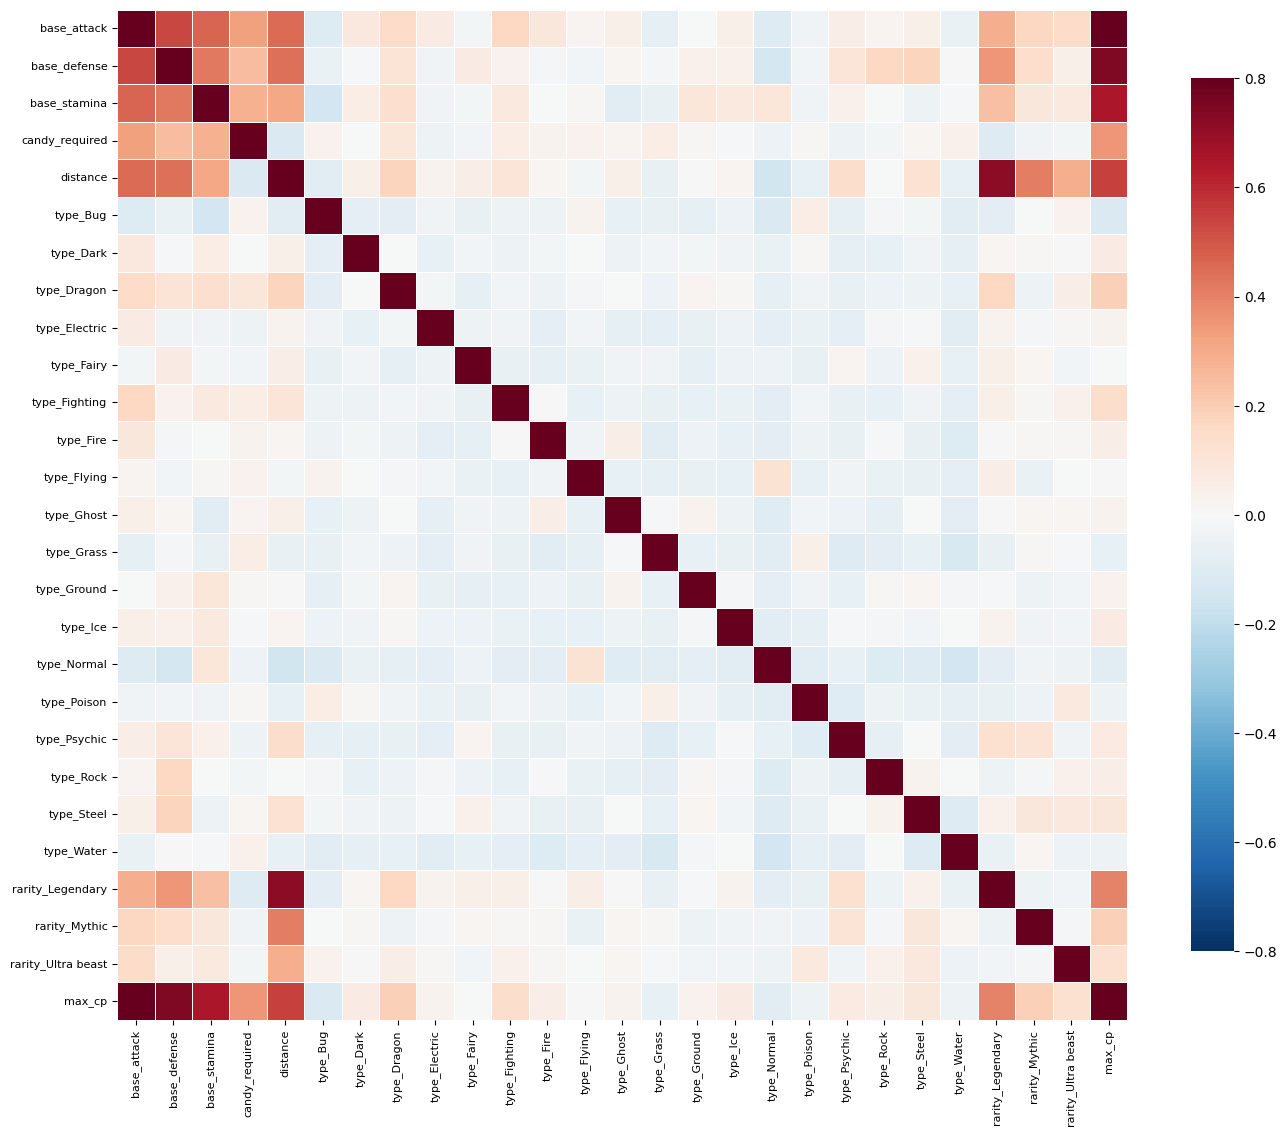

In [17]:
corr = pd.concat([df2, y], axis=1).corr()

plt.figure(figsize=(14, 12))
sns.heatmap(
    corr,
    cmap="RdBu_r",
    center=0,
    vmin=-0.8,
    vmax=0.8,
    square=True,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"shrink": 0.8}
)
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.show()

**Analisis Heatmap Korelasi**:
- **Korelasi Sangat Kuat**: Atribut statistik dasar menunjukkan korelasi positif yang sangat dominan terhadap `max_cp`, dengan `base_attack` memiliki nilai korelasi tertinggi ($r \approx 0.94$), diikuti oleh `base_defense` ($r \approx 0.83$) dan `base_stamina` ($r \approx 0.77$). Pola ini selaras dengan formula deterministik game di mana serangan menjadi komponen utama perhitungan CP.
- **Korelasi Kelangkaan**: Fitur `rarity_Legendary` dan `rarity_Mythic` memiliki korelasi positif terhadap target, menegaskan bahwa tingkatan kelangkaan berhubungan langsung dengan batas atas potensi kekuatan Pokémon.
- **Korelasi Tipe Elemental**: Kolom biner tipe elemental memiliki korelasi linear yang moderat hingga rendah terhadap target kontinu, namun berfungsi sebagai pembeda karakteristik pada sub-populasi data.

### C. Verifikasi Struktur Dataset Sebelum Deteksi Anomali
Memeriksa kembali tipe data dan jumlah kolom DataFrame `df2` sebelum masuk ke proses deteksi dan penyaringan anomali data.

In [18]:
df2.info()

<class 'pandas.DataFrame'>
RangeIndex: 1007 entries, 0 to 1006
Data columns (total 26 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   base_attack         1007 non-null   int64  
 1   base_defense        1007 non-null   int64  
 2   base_stamina        1007 non-null   int64  
 3   candy_required      1007 non-null   float64
 4   distance            1007 non-null   int64  
 5   type_Bug            1007 non-null   int64  
 6   type_Dark           1007 non-null   int64  
 7   type_Dragon         1007 non-null   int64  
 8   type_Electric       1007 non-null   int64  
 9   type_Fairy          1007 non-null   int64  
 10  type_Fighting       1007 non-null   int64  
 11  type_Fire           1007 non-null   int64  
 12  type_Flying         1007 non-null   int64  
 13  type_Ghost          1007 non-null   int64  
 14  type_Grass          1007 non-null   int64  
 15  type_Ground         1007 non-null   int64  
 16  type_Ice         

### D. Deteksi Anomali Data & Metodologi Penanganan Outlier

Dalam proyek ini diterapkan pembedaan yang tegas antara **pencilan sah (*legitimate outliers*)** dan **anomali data rusak (*corrupted anomalies*)**:
1. **Pencilan Sah Dipertahankan**: Pokémon tier Legendary/Mythic (seperti Mewtwo, Rayquaza, Slaking) dengan `max_cp` > 4000 atau Pokémon spesialis seperti Blissey (stamina ekstrem ~496) dan Shuckle (defense ekstrem ~396) adalah data resmi dan sah (*ground truth*) dari mekanisme game Pokémon GO. Menghapus data ini akan memicu *underestimation bias* pada model dan menghilangkan representasi Pokémon terkuat.
2. **Anomali Rusak Dieliminasi**: Pokémon dengan statistik dasar (`base_attack`, `base_defense`, atau `base_stamina`) bernilai $\le 0$ adalah data tidak lengkap / placeholder cacat yang mustahil ada dalam logika permainan, sehingga wajib disaring.

Berikut dilakukan deteksi terhadap baris-baris data yang memiliki nilai statistik dasar bernilai 0.

In [19]:
stat_cols = ["base_attack", "base_defense", "base_stamina"]
anomali = (df2[stat_cols] == 0).any(axis=1)
pd.concat([df2[anomali], y[anomali]], axis=1)

,base_attack,base_defense,base_stamina,candy_required,distance,type_Bug,type_Dark,type_Dragon,type_Electric,type_Fairy,...,type_Normal,type_Poison,type_Psychic,type_Rock,type_Steel,type_Water,rarity_Legendary,rarity_Mythic,rarity_Ultra beast,max_cp
678,0,0,0,0.0,5,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,16
679,0,0,0,25.0,5,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,16
680,0,0,0,100.0,5,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,16


Menyaring dan menghapus baris anomali agar hanya menyisakan data dengan statistik dasar yang valid ($> 0$), kemudian memverifikasi dimensi akhir dataset.

In [20]:
valid = (df2[stat_cols] > 0).all(axis=1)
df2 = df2[valid]
y = y[valid]
print(df2.shape, y.shape)

(1004, 26) (1004,)


**Analisis Hasil Penyaringan Anomali**:
- Sebanyak **3 baris anomali** berhasil diidentifikasi dan dihapus (dimensi data berkurang dari 1.007 menjadi 1.004 baris valid).
- Seluruh 1.004 entri data yang tersisa memiliki statistik dasar yang valid dan siap diproses ke tahap pembagian data.

### E. Pembagian Data Latih dan Data Uji (Data Splitting)
Membagi dataset menjadi data latih (*training set* sebesar 80% = 803 sampel) dan data uji (*testing set* sebesar 20% = 201 sampel) menggunakan `train_test_split` dengan parameter `random_state=42` untuk memastikan keterulangan hasil (*reproducibility*).

In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df2, y, test_size=0.2, random_state=42
)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(803, 26) (201, 26) (803,) (201,)


### F. Pemeriksaan Statistik Fitur Numerik Sebelum Standardisasi
Melihat ringkasan nilai rata-rata (*mean*) dan standar deviasi (*std*) pada fitur numerik data latih sebelum dilakukan penskalaan.

In [22]:
num_cols = ["base_attack", "base_defense", "base_stamina", "candy_required", "distance"]
X_train[num_cols].describe().loc[["mean", "std", "min", "max"]]

,base_attack,base_defense,base_stamina,candy_required,distance
mean,165.919054,144.566625,171.108344,30.850560,5.139477
std,59.560817,52.928399,48.648410,56.312165,5.557496
min,17.000000,32.000000,1.000000,0.000000,1.000000
max,414.000000,505.000000,496.000000,400.000000,20.000000


### G. Standardisasi Skala Fitur (StandardScaler)

Menerapkan `StandardScaler` untuk menyamakan skala fitur-fitur numerik (`base_attack`, `base_defense`, `base_stamina`, `candy_required`, `distance`) sehingga memiliki rata-rata bernilai 0 dan variansi bernilai 1:
- `scaler.fit_transform()` diterapkan **hanya pada data latih** (`X_train`).
- `scaler.transform()` diterapkan **pada data uji** (`X_test`).

Metodologi ini mencegah terjadinya kebocoran informasi (*data leakage*) dari himpunan data uji ke dalam proses pelatihan.

In [23]:
scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

X_train_scaled.head()

,base_attack,base_defense,base_stamina,candy_required,distance,type_Bug,type_Dark,type_Dragon,type_Electric,type_Fairy,...,type_Ice,type_Normal,type_Poison,type_Psychic,type_Rock,type_Steel,type_Water,rarity_Legendary,rarity_Mythic,rarity_Ultra beast
78,-0.956242,-0.880352,0.738236,-0.548190,-0.385211,0,0,0,0,0,...,0,0,0,1,0,0,1,0,0,0
29,-0.821841,-0.464438,0.018340,-0.103960,-0.385211,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
280,-0.821841,-1.031594,-1.133494,-0.103960,-0.025113,0,0,0,0,1,...,0,0,0,1,0,0,0,0,0,0
507,0.673361,0.707686,0.553120,1.228732,-0.745310,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
652,-0.838641,-0.804732,-1.051220,-0.548190,-0.385211,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Memeriksa nilai rata-rata (*mean*) dan standar deviasi (*std*) pada data latih hasil transformasi untuk memverifikasi bahwa seluruh fitur numerik telah terstandarisasi dengan sempurna (mean mendekati 0 dan std bernilai 1).

In [24]:
X_train_scaled[num_cols].describe().loc[["mean", "std"]].round(3)

,base_attack,base_defense,base_stamina,candy_required,distance
mean,0.000,-0.000,-0.000,0.000,0.000
std,1.001,1.001,1.001,1.001,1.001


## 4. Pemodelan Machine Learning (Linear Regression & Logistic Regression)

Pada tahap ini, dilakukan pembangunan dan pengujian dua model machine learning utama:
1. **Linear Regression**: Untuk memprediksi nilai kontinu `max_cp` Pokémon (Kasus Regresi).
2. **Logistic Regression**: Untuk mengklasifikasikan tingkatan kekuatan Pokémon menjadi kategori CP Rendah vs CP Tinggi dilengkapi evaluasi **Confusion Matrix** (Kasus Klasifikasi).
3. **Ekspor Model**: Menyimpan model terlatih dan transformer ke format `.joblib` untuk kebutuhan inferensi/deployment.

Mengimpor model Linear Regression, Logistic Regression, metrik evaluasi regresi dan klasifikasi, serta library `joblib`.

In [25]:
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    confusion_matrix, classification_report, accuracy_score, ConfusionMatrixDisplay
)
import joblib

### A. Pemodelan Regresi dengan Linear Regression
Melatih model **Linear Regression** pada data latih yang telah distandardisasi (`X_train_scaled`) untuk memprediksi nilai target kontinu `max_cp` (`y_train`), lalu mengevaluasinya pada data uji (`X_test_scaled`).

In [26]:
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

y_pred_train_lr = lr_model.predict(X_train_scaled)
y_pred_test_lr = lr_model.predict(X_test_scaled)

lr_mae = mean_absolute_error(y_test, y_pred_test_lr)
lr_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test_lr))
lr_r2_train = r2_score(y_train, y_pred_train_lr)
lr_r2_test = r2_score(y_test, y_pred_test_lr)

print("=== Hasil Evaluasi Linear Regression ===")
print(f"MAE      : {lr_mae:.4f}")
print(f"RMSE     : {lr_rmse:.4f}")
print(f"R2 Train : {lr_r2_train:.4f}")
print(f"R2 Test  : {lr_r2_test:.4f}")

=== Hasil Evaluasi Linear Regression ===
MAE      : 99.7804
RMSE     : 135.9011
R2 Train : 0.9764
R2 Test  : 0.9825


**Analisis Hasil Linear Regression**:
- Skor $R^2$ latih (0.9764) dan $R^2$ uji (0.9825) sangat seimbang dan tinggi, mengonfirmasi model memiliki generalisasi yang sangat baik tanpa tanda-tanda overfitting.
- Model berhasil menjelaskan lebih dari 98.2% variansi nilai `max_cp` pada data uji, dengan rata-rata kesalahan absolut (MAE) sebesar 99.78 CP dan RMSE sebesar 135.90 CP.

Membuat visualisasi perbandingan nilai aktual vs prediksi serta plot residual untuk memvalidasi performa model regresi.

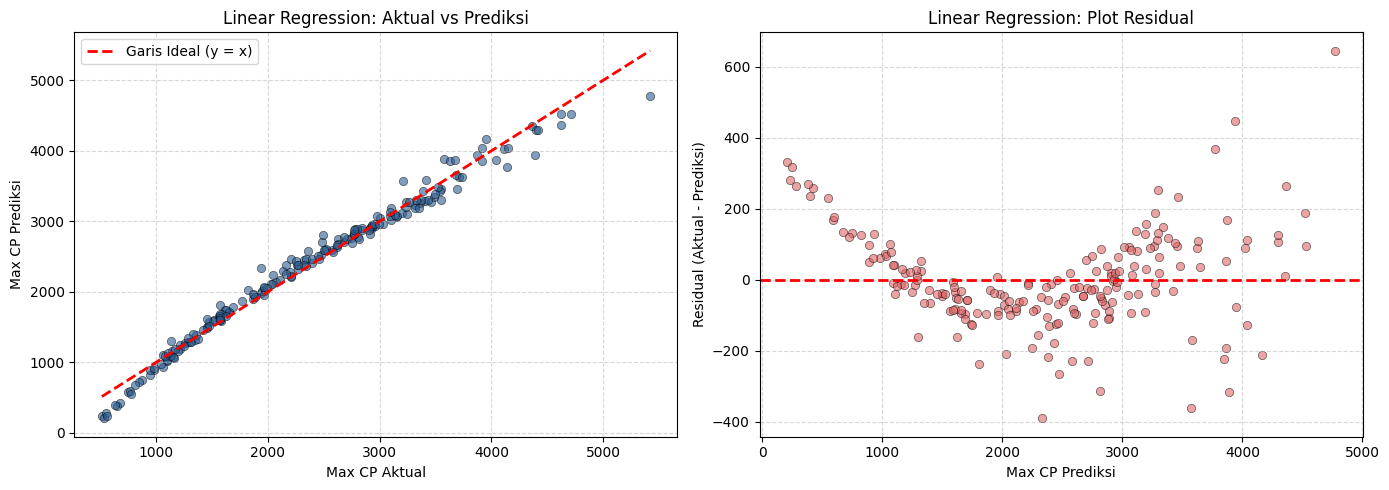

In [27]:
resid_lr = y_test - y_pred_test_lr

plt.figure(figsize=(14, 5))

# Subplot 1: Aktual vs Prediksi
plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred_test_lr, alpha=0.6, color="#2b5c8f", edgecolor="k", linewidth=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", lw=2, label="Garis Ideal (y = x)")
plt.xlabel("Max CP Aktual")
plt.ylabel("Max CP Prediksi")
plt.title("Linear Regression: Aktual vs Prediksi")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

# Subplot 2: Plot Residual
plt.subplot(1, 2, 2)
plt.scatter(y_pred_test_lr, resid_lr, alpha=0.6, color="#e06666", edgecolor="k", linewidth=0.5)
plt.axhline(0, color="red", linestyle="--", lw=2)
plt.xlabel("Max CP Prediksi")
plt.ylabel("Residual (Aktual - Prediksi)")
plt.title("Linear Regression: Plot Residual")
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

**Analisis Visualisasi Regresi**:
Persebaran titik pada grafik Aktual vs Prediksi membentuk garis diagonal yang rapat, menandakan akurasi prediksi yang tinggi di seluruh rentang nilai CP. Plot residual memperlihatkan sebaran acak di sekitar sumbu nol tanpa pola heteroskedastisitas yang berarti.

### B. Pemodelan Klasifikasi dengan Logistic Regression & Confusion Matrix

Logistic Regression membutuhkan variabel target diskret/kategorikal. Kita mengelompokkan nilai Max CP menjadi dua kategori berbasis median (`2312.50`):
- **0 (CP Rendah)**: Nilai Max CP di bawah median.
- **1 (CP Tinggi)**: Nilai Max CP di atas atau sama dengan median.

Dengan pendekatan ini, data target menjadi seimbang (*balanced classes*) sehingga evaluasi klasifikasi menggunakan Confusion Matrix menjadi objektif dan valid.

In [28]:
median_cp = y.median()
print(f"Median Max CP: {median_cp:.2f}")

# Membuat target biner: 0 = CP Rendah, 1 = CP Tinggi
y_train_cls = (y_train >= median_cp).astype(int)
y_test_cls = (y_test >= median_cp).astype(int)

print("Distribusi target latih (y_train_cls):")
print(y_train_cls.value_counts(normalize=True).round(4))
print("\nDistribusi target uji (y_test_cls):")
print(y_test_cls.value_counts(normalize=True).round(4))

Median Max CP: 2312.50
Distribusi target latih (y_train_cls):
max_cp
0    0.5031
1    0.4969
Name: proportion, dtype: float64

Distribusi target uji (y_test_cls):
max_cp
1    0.5124
0    0.4876
Name: proportion, dtype: float64


Melatih model **Logistic Regression** menggunakan data latih terstandarisasi (`X_train_scaled`, `y_train_cls`) dan mengevaluasi performanya pada data uji (`X_test_scaled`, `y_test_cls`).

In [29]:
logreg_model = LogisticRegression(random_state=42, max_iter=1000)
logreg_model.fit(X_train_scaled, y_train_cls)

y_pred_cls = logreg_model.predict(X_test_scaled)
acc_lr = accuracy_score(y_test_cls, y_pred_cls)

print(f"Akurasi Logistic Regression: {acc_lr:.4f} ({acc_lr*100:.2f}%)\n")
print("=== Classification Report ===")
print(classification_report(y_test_cls, y_pred_cls, target_names=["CP Rendah (0)", "CP Tinggi (1)"]))

Akurasi Logistic Regression: 0.9900 (99.00%)

=== Classification Report ===
               precision    recall  f1-score   support

CP Rendah (0)       0.99      0.99      0.99        98
CP Tinggi (1)       0.99      0.99      0.99       103

     accuracy                           0.99       201
    macro avg       0.99      0.99      0.99       201
 weighted avg       0.99      0.99      0.99       201



Membuat visualisasi **Confusion Matrix** untuk menganalisis secara detail hasil klasifikasi (True Positive, True Negative, False Positive, dan False Negative).

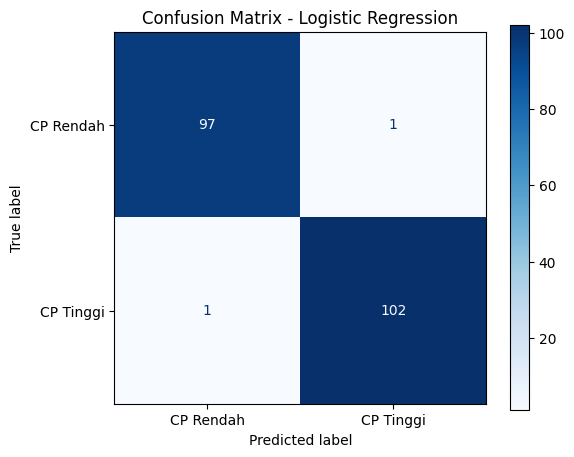

True Negative (TN) : 97 (CP Rendah diprediksi benar)
False Positive (FP): 1 (CP Rendah keliru diprediksi sebagai CP Tinggi)
False Negative (FN): 1 (CP Tinggi keliru diprediksi sebagai CP Rendah)
True Positive (TP) : 102 (CP Tinggi diprediksi benar)


In [30]:
cm = confusion_matrix(y_test_cls, y_pred_cls)

plt.figure(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["CP Rendah", "CP Tinggi"])
disp.plot(cmap="Blues", values_format="d", ax=plt.gca())
plt.title("Confusion Matrix - Logistic Regression")
plt.grid(False)
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True Negative (TN) : {tn} (CP Rendah diprediksi benar)")
print(f"False Positive (FP): {fp} (CP Rendah keliru diprediksi sebagai CP Tinggi)")
print(f"False Negative (FN): {fn} (CP Tinggi keliru diprediksi sebagai CP Rendah)")
print(f"True Positive (TP) : {tp} (CP Tinggi diprediksi benar)")

**Analisis Confusion Matrix**:
- Dari total 201 data uji, model memprediksi dengan benar sebanyak **199 data** (97 CP Rendah dan 102 CP Tinggi).
- Kesalahan klasifikasi hanya terjadi pada **2 sampel** (1 False Positive dan 1 False Negative), dengan akurasi pengujian mencapai **99.00%**.
- Hasil evaluasi membuktikan bahwa kombinasi statistik dasar (*base attack*, *defense*, *stamina*), tipe, dan tingkat kelangkaan memiliki daya pembeda yang sangat akurat dalam mengklasifikasikan tingkatan kekuatan Pokémon.

### C. Ekspor Model ke File .joblib
Menyimpan model Linear Regression, Logistic Regression, dan StandardScaler ke dalam format `.joblib` agar dapat dimuat kembali (*persisted*) untuk keperluan produksi atau deployment aplikasi.

In [31]:
# Menyimpan model dan scaler ke format .joblib
joblib.dump(lr_model, "linear_regression_model.joblib")
joblib.dump(logreg_model, "logistic_regression_model.joblib")
joblib.dump(scaler, "scaler.joblib")

print("Model berhasil disimpan ke format joblib:")
print("1. linear_regression_model.joblib")
print("2. logistic_regression_model.joblib")
print("3. scaler.joblib")

Model berhasil disimpan ke format joblib:
1. linear_regression_model.joblib
2. logistic_regression_model.joblib
3. scaler.joblib


Memverifikasi kedua model yang telah diekspor dengan memuatnya kembali (`joblib.load`) dan menjalankan inferensi pada 5 sampel data uji.

In [32]:
# Verifikasi pengujian reload model dari file joblib
loaded_lr = joblib.load("linear_regression_model.joblib")
loaded_logreg = joblib.load("logistic_regression_model.joblib")
loaded_scaler = joblib.load("scaler.joblib")

sample_data = X_test_scaled.iloc[:5]
pred_sample_cp = loaded_lr.predict(sample_data)
pred_sample_cls = loaded_logreg.predict(sample_data)
label_map = {0: "CP Rendah", 1: "CP Tinggi"}

df_verif = pd.DataFrame({
    "Max CP Aktual": y_test.iloc[:5].values,
    "Prediksi Linear Reg (CP)": pred_sample_cp.round(1),
    "Prediksi Logistic Reg": [label_map[p] for p in pred_sample_cls]
})
df_verif

,Max CP Aktual,Prediksi Linear Reg (CP),Prediksi Logistic Reg
0,2257,2386.7,CP Rendah
1,2740,2766.5,CP Tinggi
2,1061,932.2,CP Rendah
3,1094,1022.0,CP Rendah
4,1453,1499.6,CP Rendah


## 5. Ringkasan dan Kesimpulan Akhir

1. **Performa Linear Regression (Regresi)**:
   - Bertujuan memprediksi nilai kontinu `max_cp` Pokémon.
   - Menghasilkan performa optimal dan seimbang: **$R^2$ Latih = 0.9764**, **$R^2$ Uji = 0.9825**, dan **MAE = 99.78 CP**.

2. **Performa Logistic Regression & Confusion Matrix (Klasifikasi)**:
   - Bertujuan mengklasifikasikan Pokémon ke dalam kategori *CP Rendah* vs *CP Tinggi* berbasis nilai median data.
   - Menghasilkan akurasi sebesar **99.00%** pada data uji.
   - Visualisasi Confusion Matrix mencatat 199 prediksi benar dan hanya terdapat 2 kesalahan prediksi dari total 201 data uji.

3. **Deployment & Export (.joblib)**:
   - Model dan transformer telah diekspor dan diverifikasi ke dalam file `.joblib`:
     - `linear_regression_model.joblib` (Model Regresi)
     - `logistic_regression_model.joblib` (Model Klasifikasi)
     - `scaler.joblib` (StandardScaler)
   - Pipeline inferensi telah diuji kembali menggunakan `joblib.load` dan siap digunakan.